# Research Question 1

Within the same firm, do former and current employees rate differently?

# 0. Setup

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

# 1. Data Preparation

In [2]:
processed_path = '../data/processed/processed.parquet'

df = pd.read_parquet(processed_path)

In [7]:
df.columns

Index(['firm_id', 'rating', 'former', 'emp_type', 'tenure', 'year', 'date',
       'number of reviews', 'cons', 'job'],
      dtype='str')

In [57]:
overall_means = df.groupby("former")["rating"].mean()
overall_gap = overall_means[1] - overall_means[0]
print(overall_gap)

-0.4999101794668488


In [28]:
# Create sample
# Firms must have reviews from at least 10 current and at least 10 former employees

sample_df = df.groupby("firm_id").filter(
    lambda g: (g["former"] == 1).sum() >= 10 and (g["former"] == 0).sum() >= 10
)

In [29]:
len(sample_df)

4842081

In [58]:
# Calculate pooled gap against sample

sample_means = sample_df.groupby("former")["rating"].mean()
sample_gap = sample_means[1] - sample_means[0]
print(sample_gap)

-0.49288590280657374


# 2. Experiment

In [ ]:
# Calculate each firm's gap between former and current reviews
pivot_table  = pd.pivot_table(
    data=sample_df,
    index="firm_id",
    columns="former",
    values="rating",
    aggfunc='mean'
)

pivot_table["gap"] = pivot_table[1] - pivot_table[0]

print(pivot_table)

former          0         1       gap
firm_id                              
4        3.448598  3.029126 -0.419472
7        4.067416  2.747967 -1.319448
8        3.907563  3.633760 -0.273803
12       3.902266  3.541667 -0.360599
14       3.681818  3.160000 -0.521818
...           ...       ...       ...
6943496  3.750000  2.533333 -1.216667
6970005  3.833333  2.705882 -1.127451
7322951  3.928571  3.250000 -0.678571
8120105  4.238095  4.000000 -0.238095
8432188  3.982497  3.795273 -0.187224

[8539 rows x 3 columns]


In [ ]:
gaps = pivot_table["gap"]
gaps_mean = gaps.mean()
gaps_se = np.std(gaps, ddof=1) / np.sqrt(len(gaps)) # ddof=1: divided by n-1 for sample

In [49]:
# Calculate 95% Confidence Interval
lower_band = gaps_mean - 1.96 * gaps_se
upper_band = gaps_mean + 1.96 * gaps_se

print(f"95% Confidence Interval of rating gaps between former and current employees is {lower_band} ~ {upper_band}.")

95% Confidence Interval of rating gaps between former and current employees is -0.6039046384099692 ~ -0.5835901018433661.


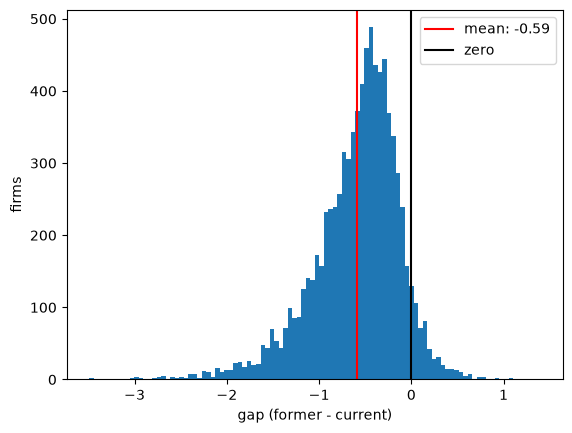

In [50]:
# Visualize gaps' distribution

plt.hist(gaps, bins=100)
plt.axvline(gaps_mean, color="red", label=f'mean: {round(gaps_mean, 2)}')
plt.axvline(0, color="black", label='zero')
plt.xlabel("gap (former - current)")
plt.ylabel("firms")
plt.legend()
plt.show()

# 3. Result

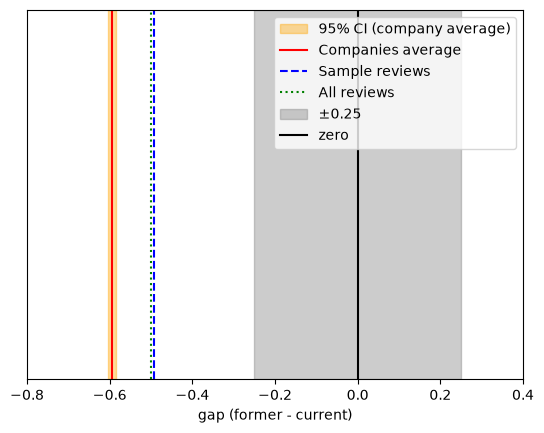

In [ ]:
plt.axvspan(lower_band, upper_band, color="orange", alpha=0.4, label="95% CI (firm average)")
plt.axvline(gaps_mean, color="red", label="Firm average")
plt.axvline(sample_gap, color="blue", linestyle="--", label="Sample reviews")
plt.axvline(overall_gap, color="green", linestyle=":", label="All reviews")
plt.axvspan(-0.25, +0.25, color="gray", alpha=0.4, label="±0.25")
plt.axvline(0, color="black", label="zero")
plt.xlim(-0.8, 0.4)
plt.xlabel("gap (former - current)")
plt.yticks([])
plt.legend()
plt.show()

In [ ]:
gaps.rename("gap").to_frame().to_parquet("../data/processed/rq1/rq1_gaps.parquet")

summary = {
    "overall_gap": float(overall_gap),
    "sample_gap": float(sample_gap),
    "gaps_mean": float(gaps_mean),
}
with open("../data/processed/rq1/rq1_summary.json", "w") as f:
    json.dump(summary, f)